In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
phonepe = pd.read_excel(r"C:\Users\PRATHAM\OneDrive\Desktop\Coding Ninjas\Pyhton projects\Python project phone pay\phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752.xlsx", sheet_name=None)

C:\Users\PRATHAM\anaconda3\Lib\site-packages\openpyxl\worksheet\header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


In [3]:
state_txn_and_users = phonepe["State_Txn and Users"]
state_txnsplit = phonepe["State_TxnSplit"]
state_devicedata = phonepe["State_DeviceData"]
district_txn_and_users = phonepe["District_Txn and Users"]
district_demographics = phonepe["District Demographics"]

In [4]:
state_txnsplit.head()

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1.845307e+06,439.358921
1,Andaman & Nicobar Islands,2018,1,Peer-to-peer payments,1871,1.213866e+07,6487.790112
2,Andaman & Nicobar Islands,2018,1,Merchant payments,298,4.525072e+05,1518.480432
3,Andaman & Nicobar Islands,2018,1,Financial Services,33,1.060142e+04,321.255149
4,Andaman & Nicobar Islands,2018,1,Others,256,1.846899e+05,721.444790


In [5]:
state_txn_and_users.describe()

,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
count,504.000000,504.000000,5.040000e+02,5.030000e+02,504.000000,5.040000e+02,5.040000e+02
mean,2019.285714,2.357143,4.074000e+07,7.083332e+10,1993.471543,4.777501e+06,9.774471e+07
std,1.031181,1.109971,8.228714e+07,1.440902e+11,607.464894,6.644496e+06,2.042376e+08
min,2018.000000,1.000000,7.780000e+02,1.928611e+06,0.000000,5.010000e+02,0.000000e+00
25%,2018.000000,1.000000,5.925578e+05,1.167157e+09,1598.910667,1.574202e+05,0.000000e+00
50%,2019.000000,2.000000,6.217487e+06,1.051605e+10,1861.380589,1.747914e+06,2.930574e+06
75%,2020.000000,3.000000,4.363675e+07,6.947045e+10,2259.087924,7.320945e+06,8.615022e+07
max,2021.000000,4.000000,5.736165e+08,1.027958e+12,3938.733850,3.966470e+07,1.208084e+09


In [6]:
state_txn_and_users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   State             504 non-null    object 
 1   Year              504 non-null    int64  
 2   Quarter           504 non-null    int64  
 3   Transactions      504 non-null    int64  
 4   Amount (INR)      503 non-null    float64
 5   ATV (INR)         504 non-null    float64
 6   Registered Users  504 non-null    int64  
 7   App Opens         504 non-null    int64  
dtypes: float64(2), int64(5), object(1)
memory usage: 31.6+ KB


## Display basic statistics and data types for each dataset

In [7]:
datasets = {
    "State_Txn and Users": state_txn_and_users,
    "State_TxnSplit": state_txnsplit,
    "State_DeviceData": state_devicedata,
    "District_Txn and Users": district_txn_and_users,
    "District Demographics": district_demographics
}

# STEP 1: Initial Data Profiling

for name, df in datasets.items():

    print("\n" + "=" * 70)
    print(f"DATASET: {name}")
    print("=" * 70)

    print("Number of rows:", df.shape[0])
    print("Number of columns:", df.shape[1])

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nSummary statistics:")
    display(df.describe(include="all").T)


DATASET: State_Txn and Users
Number of rows: 504
Number of columns: 8

Column names:
['State', 'Year', 'Quarter', 'Transactions', 'Amount (INR)', 'ATV (INR)', 'Registered Users', 'App Opens']

Data types:
State                object
Year                  int64
Quarter               int64
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
Registered Users      int64
App Opens             int64
dtype: object

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State,504,36,Andaman & Nicobar Islands,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,504.0,NaN,NaN,NaN,2019.285714,1.031181,2018.0,2018.0,2019.0,2020.0,2021.0
Quarter,504.0,NaN,NaN,NaN,2.357143,1.109971,1.0,1.0,2.0,3.0,4.0
Transactions,504.0,NaN,NaN,NaN,40740000.583333,82287143.485579,778.0,592557.75,6217487.0,43636745.5,573616486.0
Amount (INR),503.0,NaN,NaN,NaN,70833320601.589218,144090233156.008606,1928611.180878,1167157028.934341,10516054014.086979,69470450912.083282,1027958332797.583618
ATV (INR),504.0,NaN,NaN,NaN,1993.471543,607.464894,0.0,1598.910667,1861.380589,2259.087924,3938.73385
Registered Users,504.0,NaN,NaN,NaN,4777500.886905,6644495.720725,501.0,157420.25,1747914.0,7320945.25,39664697.0
App Opens,504.0,NaN,NaN,NaN,97744705.228175,204237579.801467,0.0,0.0,2930573.5,86150218.25,1208083592.0



DATASET: State_TxnSplit
Number of rows: 2514
Number of columns: 7

Column names:
['State', 'Year', 'Quarter', 'Transaction Type', 'Transactions', 'Amount (INR)', 'ATV (INR)']

Data types:
State                object
Year                  int64
Quarter               int64
Transaction Type     object
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
dtype: object

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State,2514,36,Andaman & Nicobar Islands,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,2514.0,NaN,NaN,NaN,2019.286794,1.030807,2018.0,2018.0,2019.0,2020.0,2021.0
Quarter,2514.0,NaN,NaN,NaN,2.358393,1.109251,1.0,1.0,2.0,3.0,4.0
Transaction Type,2514,5,Recharge & bill payments,504,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transactions,2514.0,NaN,NaN,NaN,8167446.417661,24236453.681352,2.0,27880.75,268798.0,3683230.25,279599017.0
Amount (INR),2514.0,NaN,NaN,NaN,14439779209.536989,59950544781.054909,34.397212,17624121.726837,190118948.889149,2661247757.003218,872151973637.88501
ATV (INR),2514.0,NaN,NaN,NaN,1349.927929,1534.866221,17.198606,385.735827,720.940406,1352.790116,7767.539936



DATASET: State_DeviceData
Number of rows: 5544
Number of columns: 6

Column names:
['State', 'Year', 'Quarter', 'Brand', 'Registered Users', 'Percentage']

Data types:
State                object
Year                  int64
Quarter               int64
Brand                object
Registered Users      int64
Percentage          float64
dtype: object

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State,5544,36,Andaman & Nicobar Islands,154,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,5544.0,NaN,NaN,NaN,2019.285714,1.03025,2018.0,2018.0,2019.0,2020.0,2021.0
Quarter,5544.0,NaN,NaN,NaN,2.357143,1.10897,1.0,1.0,2.0,3.0,4.0
Brand,5544,20,Xiaomi,504,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Registered Users,5544.0,NaN,NaN,NaN,434318.262446,905606.949794,10.0,8055.75,74422.5,397887.5,9764252.0
Percentage,5544.0,NaN,NaN,NaN,0.090909,0.083095,0.006373,0.021588,0.056914,0.143626,0.478367



DATASET: District_Txn and Users
Number of rows: 10248
Number of columns: 10

Column names:
['State', 'Year', 'Quarter', 'District', 'Code', 'Transactions', 'Amount (INR)', 'ATV (INR)', 'Registered Users', 'App Opens']

Data types:
State                object
Year                  int64
Quarter               int64
District             object
Code                 object
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
Registered Users      int64
App Opens             int64
dtype: object

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State,10248,36,Uttar Pradesh,1050,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,10248.0,NaN,NaN,NaN,2019.285714,1.030208,2018.0,2018.0,2019.0,2020.0,2021.0
Quarter,10248.0,NaN,NaN,NaN,2.357143,1.108924,1.0,1.0,2.0,3.0,4.0
District,10248,723,Balrampur,28,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Code,10220,730,WB23,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transactions,10248.0,NaN,NaN,NaN,2003606.586066,9613466.292188,0.0,103141.75,376306.5,1272815.0,348712787.0
Amount (INR),10248.0,NaN,NaN,NaN,3542311176.110069,14731537479.503397,0.0,175666805.606704,678456240.45592,2377255936.79888,444422398357.677002
ATV (INR),10244.0,NaN,NaN,NaN,1909.796545,600.943349,84.944283,1554.589051,1863.13553,2203.083552,11209.98055
Registered Users,10248.0,NaN,NaN,NaN,234959.060012,460597.827572,22.0,36195.5,106764.0,257316.5,10604609.0
App Opens,10248.0,NaN,NaN,NaN,4807116.650566,15625414.79737,0.0,0.0,640302.5,4346319.5,554419656.0



DATASET: District Demographics
Number of rows: 742
Number of columns: 8

Column names:
['State', 'District', 'Headquarters', 'Population', 'Area (sq km)', 'Density', 'Code', 'Alternate Name']

Data types:
State              object
District           object
Headquarters       object
Population          int64
Area (sq km)      float64
Density             int64
Code               object
Alternate Name     object
dtype: object

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
State,742,36,Uttar Pradesh,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN
District,742,736,Bijapur,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Headquarters,742,733,Bangalore,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Population,742.0,NaN,NaN,NaN,1668554.614555,1458849.180854,0.0,653081.5,1322359.0,2297440.0,10082852.0
Area (sq km),742.0,NaN,NaN,NaN,4395.37312,4254.676124,0.0,2039.75,3402.5,5432.75,45652.0
Density,742.0,NaN,NaN,NaN,838.512129,2754.406896,0.0,198.0,353.0,686.25,36155.0
Code,742,742,PY04,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Alternate Name,742,733,Balrampur,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Check for missing values

In [8]:
# STEP 2: Missing Value Analysis

missing_reports = {}

for name, df in datasets.items():

    missing_count = df.isna().sum()

    missing_percentage = (
        df.isna().mean() * 100
    ).round(2)

    report = pd.DataFrame({
        "Missing Count": missing_count,
        "Missing Percentage": missing_percentage
    })

    report = report[
        report["Missing Count"] > 0
    ].sort_values(
        "Missing Percentage",
        ascending=False
    )

    missing_reports[name] = report

    print("\n" + "=" * 60)
    print(f"MISSING VALUES: {name}")
    print("=" * 60)

    if report.empty:
        print("No missing values found.")
    else:
        display(report)


MISSING VALUES: State_Txn and Users


,Missing Count,Missing Percentage
Amount (INR),1,0.2



MISSING VALUES: State_TxnSplit
No missing values found.

MISSING VALUES: State_DeviceData
No missing values found.

MISSING VALUES: District_Txn and Users


,Missing Count,Missing Percentage
Code,28,0.27
ATV (INR),4,0.04



MISSING VALUES: District Demographics
No missing values found.


In [9]:
# STEP 3: Standardize Text Columns

text_columns = [
    "State",
    "District",
    "Transaction_type",
    "Transaction Type",
    "Brand",
    "Device Brand"
]

for name, df in datasets.items():

    for col in text_columns:

        if col in df.columns:

            df[col] = (
                df[col]
                .astype("string")
                .str.strip()
                .str.replace(
                    r"\s+",
                    " ",
                    regex=True
                )
            )

    print(f"Text standardization completed: {name}")

Text standardization completed: State_Txn and Users
Text standardization completed: State_TxnSplit
Text standardization completed: State_DeviceData
Text standardization completed: District_Txn and Users
Text standardization completed: District Demographics


In [10]:
district_txn_and_users[district_txn_and_users["District"].isin(("Mirpur","Muzaffarabad"))]

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
3133,Jammu & Kashmir,2018,1,Mirpur,NaN,1320,3.052182e+06,2312.259022,544,0
3134,Jammu & Kashmir,2018,1,Muzaffarabad,NaN,13,1.455980e+04,1119.984877,41,0
3155,Jammu & Kashmir,2018,2,Mirpur,NaN,1885,4.089199e+06,2169.336200,795,0
3156,Jammu & Kashmir,2018,2,Muzaffarabad,NaN,75,3.688235e+05,4917.646448,57,0
3177,Jammu & Kashmir,2018,3,Mirpur,NaN,2789,7.804798e+06,2798.421577,1133,0
3178,Jammu & Kashmir,2018,3,Muzaffarabad,NaN,211,5.818788e+05,2757.719318,89,0
3199,Jammu & Kashmir,2018,4,Mirpur,NaN,4525,1.719850e+07,3800.773896,1515,0
3200,Jammu & Kashmir,2018,4,Muzaffarabad,NaN,267,1.159496e+06,4342.683080,136,0
3221,Jammu & Kashmir,2019,1,Mirpur,NaN,4690,1.700625e+07,3626.065915,1891,0
3222,Jammu & Kashmir,2019,1,Muzaffarabad,NaN,309,8.026343e+05,2597.522028,170,0


In [11]:
# Create a dictionary of District and Code
district_code_dict = (
    district_txn_and_users
    .dropna(subset=["Code"])
    .drop_duplicates("District")
    .set_index("District")["Code"]
    .to_dict()
)

district_code_dict.update({
    "Muzaffarabad": "811",
    "Mirpur": "832"
})

# Fill missing Code values using the District name
district_txn_and_users["Code"] = (
    district_txn_and_users["Code"].fillna(
        district_txn_and_users["District"].map(district_code_dict)
    )
)

# Check remaining missing values
print("Missing codes:", district_txn_and_users["Code"].isna().sum())

Missing codes: 0


In [12]:
district_txn_and_users.head()

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1.139849e+06,2158.804548,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,9.316631e+05,2107.835016,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3.072437e+06,2743.247239,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1.317863e+06,1597.409798,911,0


In [13]:
district_code_dict["Muzaffarabad"]

'811'

In [14]:
# Examine rows with missing transaction amounts
missing_amount = state_txn_and_users[
    state_txn_and_users["Amount (INR)"].isna()
]

display(missing_amount)

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
26,Andhra Pradesh,2021,1,289747970,NaN,0.0,18363733,957709447


In [15]:
# Inspect missing values across relevant columns
columns_to_check = [
    "State",
    "Year",
    "Quarter",
    "Transactions",
    "Amount (INR)",
    "Registered Users"
]

display(
    state_txn_and_users.loc[
        state_txn_and_users["Amount (INR)"].isna(),
        columns_to_check
    ]
)

,State,Year,Quarter,Transactions,Amount (INR),Registered Users
26,Andhra Pradesh,2021,1,289747970,NaN,18363733


In [16]:
# STEP 5: Investigate Missing Transaction Amounts

missing_amount = state_txn_and_users[
    state_txn_and_users["Amount (INR)"].isna()
]

print("Missing transaction amount records:", len(missing_amount))

columns_to_check = [
    "State",
    "Year",
    "Quarter",
    "Transactions",
    "Amount (INR)",
    "Registered Users"
]

available_columns = [
    col for col in columns_to_check
    if col in state_txn_and_users.columns
]

display(missing_amount[available_columns])

Missing transaction amount records: 1


,State,Year,Quarter,Transactions,Amount (INR),Registered Users
26,Andhra Pradesh,2021,1,289747970,NaN,18363733


In [17]:
# STEP 6: Investigate Missing ATV Values

missing_atv = district_txn_and_users[
    district_txn_and_users["ATV (INR)"].isna()
]

print("Missing ATV records:", len(missing_atv))

atv_columns = [
    "State",
    "District",
    "Year",
    "Quarter",
    "Transactions",
    "Amount (INR)",
    "ATV (INR)"
]

available_columns = [
    col for col in atv_columns
    if col in district_txn_and_users.columns
]

display(missing_atv[available_columns])

Missing ATV records: 4


,State,District,Year,Quarter,Transactions,Amount (INR),ATV (INR)
224,Arunachal Pradesh,Anjaw,2018,1,0,0.0,NaN
241,Arunachal Pradesh,Shi Yomi,2018,1,0,0.0,NaN
266,Arunachal Pradesh,Shi Yomi,2018,2,0,0.0,NaN
291,Arunachal Pradesh,Shi Yomi,2018,3,0,0.0,NaN


In [18]:
# STEP 7: Validate Data Types

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(f"DATA TYPES: {name}")
    print("=" * 60)

    display(
        pd.DataFrame({
            "Data Type": df.dtypes.astype(str),
            "Missing Values": df.isna().sum()
        })
    )


DATA TYPES: State_Txn and Users


,Data Type,Missing Values
State,string,0
Year,int64,0
Quarter,int64,0
Transactions,int64,0
Amount (INR),float64,1
ATV (INR),float64,0
Registered Users,int64,0
App Opens,int64,0



DATA TYPES: State_TxnSplit


,Data Type,Missing Values
State,string,0
Year,int64,0
Quarter,int64,0
Transaction Type,string,0
Transactions,int64,0
Amount (INR),float64,0
ATV (INR),float64,0



DATA TYPES: State_DeviceData


,Data Type,Missing Values
State,string,0
Year,int64,0
Quarter,int64,0
Brand,string,0
Registered Users,int64,0
Percentage,float64,0



DATA TYPES: District_Txn and Users


,Data Type,Missing Values
State,string,0
Year,int64,0
Quarter,int64,0
District,string,0
Code,object,0
Transactions,int64,0
Amount (INR),float64,0
ATV (INR),float64,4
Registered Users,int64,0
App Opens,int64,0



DATA TYPES: District Demographics


,Data Type,Missing Values
State,string,0
District,string,0
Headquarters,object,0
Population,int64,0
Area (sq km),float64,0
Density,int64,0
Code,object,0
Alternate Name,object,0


In [19]:
# Convert numeric metrics in state transaction data

numeric_columns = [
    "Transactions",
    "Amount (INR)",
    "Registered Users",
    "App Opens"
]

for col in numeric_columns:

    if col in state_txn_and_users.columns:

        state_txn_and_users[col] = pd.to_numeric(
            state_txn_and_users[col],
            errors="coerce"
        )

In [20]:
missing_atv = district_txn_and_users[
    district_txn_and_users["ATV (INR)"].isna()
]

print("Missing ATV records:", len(missing_atv))

display(missing_atv)

Missing ATV records: 4


,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
224,Arunachal Pradesh,2018,1,Anjaw,AR01,0,0.0,NaN,278,0
241,Arunachal Pradesh,2018,1,Shi Yomi,AR17,0,0.0,NaN,49,0
266,Arunachal Pradesh,2018,2,Shi Yomi,AR17,0,0.0,NaN,80,0
291,Arunachal Pradesh,2018,3,Shi Yomi,AR17,0,0.0,NaN,118,0


In [21]:
# Fill missing ATV values with the mean of the whole column
district_txn_and_users["ATV (INR)"] = district_txn_and_users["ATV (INR)"].fillna(
    district_txn_and_users["ATV (INR)"].mean()
)

# Check remaining missing values
print("Remaining missing ATV values:",
      district_txn_and_users["ATV (INR)"].isna().sum())

Remaining missing ATV values: 0


In [22]:
# Fill missing Amount (INR) values with the mean of the whole column
state_txn_and_users["Amount (INR)"] = (
    state_txn_and_users["Amount (INR)"].fillna(
        state_txn_and_users["Amount (INR)"].mean()
    )
)

# Check remaining missing values
print(
    "Remaining missing Amount values:",
    state_txn_and_users["Amount (INR)"].isna().sum()
)

Remaining missing Amount values: 0


In [23]:
# checking for duplicates
for name, df in datasets.items():

    print(f"\n{name}")
    print("-" * 50)

    print("Total rows:", len(df))
    print("Exact duplicate rows:", df.duplicated().sum())


State_Txn and Users
--------------------------------------------------
Total rows: 504
Exact duplicate rows: 0

State_TxnSplit
--------------------------------------------------
Total rows: 2514
Exact duplicate rows: 0

State_DeviceData
--------------------------------------------------
Total rows: 5544
Exact duplicate rows: 0

District_Txn and Users
--------------------------------------------------
Total rows: 10248
Exact duplicate rows: 0

District Demographics
--------------------------------------------------
Total rows: 742
Exact duplicate rows: 0


In [24]:
# Check for negative values in key metrics
numeric_checks = [
    "Transactions",
    "Amount (INR)",
    "Registered Users",
    "App Opens"
]

for col in numeric_checks:

    if col in state_txn_and_users.columns:

        negative_count = (
            state_txn_and_users[col] < 0
        ).sum()

        print(f"{col}: {negative_count} negative values")

Transactions: 0 negative values
Amount (INR): 0 negative values
Registered Users: 0 negative values
App Opens: 0 negative values


In [25]:
def cleaning_summary(df, name):

    print(f"\nCleaning Summary: {name}")
    print("=" * 45)

    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Exact duplicates:", df.duplicated().sum())
    print("Missing cells:", df.isna().sum().sum())

    missing_percentage = (
        df.isna().mean().mul(100).round(2)
    )

    print("\nColumns with missing values:")
    print(missing_percentage[missing_percentage > 0])


for name, df in datasets.items():
    cleaning_summary(df, name)


Cleaning Summary: State_Txn and Users
Rows: 504
Columns: 8
Exact duplicates: 0
Missing cells: 0

Columns with missing values:
Series([], dtype: float64)

Cleaning Summary: State_TxnSplit
Rows: 2514
Columns: 7
Exact duplicates: 0
Missing cells: 0

Columns with missing values:
Series([], dtype: float64)

Cleaning Summary: State_DeviceData
Rows: 5544
Columns: 6
Exact duplicates: 0
Missing cells: 0

Columns with missing values:
Series([], dtype: float64)

Cleaning Summary: District_Txn and Users
Rows: 10248
Columns: 10
Exact duplicates: 0
Missing cells: 0

Columns with missing values:
Series([], dtype: float64)

Cleaning Summary: District Demographics
Rows: 742
Columns: 8
Exact duplicates: 0
Missing cells: 0

Columns with missing values:
Series([], dtype: float64)


## No of States and Districts

In [26]:

print("Total number of states:",  district_txn_and_users['State'].nunique())
print("Total number of districts:",  district_txn_and_users['District'].nunique())

Total number of states: 36
Total number of districts: 723


In [27]:
district_count = district_txn_and_users.groupby('State')['District'].nunique()

print("State with the highest number of districts:", district_count.idxmax())
print("Number of districts:", district_count.max())

State with the highest number of districts: Uttar Pradesh
Number of districts: 75


# Task 2: Exploratory Data Analysis (EDA)

# 2.1: Analyze transaction trends over the years for each state

In [28]:
state_txn_and_users.head()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,2.833854e+07,2498.989022,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,5.555747e+07,3415.768284,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,9.054834e+07,3811.277720,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,1.022997e+08,3355.630147,18596,0


### 1.⁠ ⁠Calculate the total number of transactions and total transaction amount for each state over the years. Display the results in a tabular format

In [29]:
transaction_trend = state_txn_and_users.groupby(["State","Year"],as_index = False).agg(Total_Transaction = ("Transactions","sum"),
                                        Total_Transaction_Amount_INR = ("Amount (INR)","sum")).sort_values(["State","Year"])

In [30]:
transaction_trend.head()

,State,Year,Total_Transaction,Total_Transaction_Amount_INR
0,Andaman & Nicobar Islands,2018,58021,1.890761e+08
1,Andaman & Nicobar Islands,2019,133104,4.734648e+08
2,Andaman & Nicobar Islands,2020,446274,1.296423e+09
3,Andaman & Nicobar Islands,2021,586166,1.682854e+09
4,Andhra Pradesh,2018,77779112,1.220720e+11


### 2.⁠ ⁠Identify the top 5 states with the highest transaction volumes and the top 5 states with the lowest transaction volumes Display the results.

In [31]:
transaction_volumes = state_txn_and_users.groupby("State")["Transactions"].sum()

In [32]:

Top_5_states = transaction_volumes.sort_values(ascending = False).head()

In [33]:
Top_5_states

State
Karnataka         2981044533
Maharashtra       2833670154
Telangana         2347430243
Andhra Pradesh    1781091169
Rajasthan         1382918930
Name: Transactions, dtype: int64

In [34]:
bottom_5_states = transaction_volumes.sort_values().head()

In [35]:
bottom_5_states

State
Lakshadweep                    71610
Andaman & Nicobar Islands    1223565
Ladakh                       1880109
Mizoram                      2162776
Meghalaya                    5648913
Name: Transactions, dtype: int64

## 2.2: Identify the most common transaction types in each state and quarter

###  1. For each state and quarter, determine the most frequent transaction type.Display the results in a tabular format.

In [36]:
most_frequent_transaction_type = state_txnsplit.sort_values("Transactions",ascending = False).drop_duplicates(["State","Year","Quarter"]).sort_values(["State","Year","Quarter"])

In [37]:
most_frequent_transaction_type

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200,1.845307e+06,439.358921
5,Andaman & Nicobar Islands,2018,2,Recharge & bill payments,6735,2.320945e+06,344.609463
10,Andaman & Nicobar Islands,2018,3,Recharge & bill payments,8636,4.343505e+06,502.953320
15,Andaman & Nicobar Islands,2018,4,Recharge & bill payments,11517,5.450550e+06,473.261224
20,Andaman & Nicobar Islands,2019,1,Recharge & bill payments,15263,6.611460e+06,433.169093
...,...,...,...,...,...,...,...
2489,West Bengal,2020,2,Peer-to-peer payments,24855687,8.498400e+10,3419.096979
2494,West Bengal,2020,3,Peer-to-peer payments,37556349,1.331207e+11,3544.558502
2499,West Bengal,2020,4,Peer-to-peer payments,46437233,1.663919e+11,3583.156529
2504,West Bengal,2021,1,Peer-to-peer payments,53869075,2.022402e+11,3754.292226


In [38]:
 most_frequent_transaction_type[["State", "Year", "Quarter", "Transaction Type", "Transactions"]].head(10)

,State,Year,Quarter,Transaction Type,Transactions
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200
5,Andaman & Nicobar Islands,2018,2,Recharge & bill payments,6735
10,Andaman & Nicobar Islands,2018,3,Recharge & bill payments,8636
15,Andaman & Nicobar Islands,2018,4,Recharge & bill payments,11517
20,Andaman & Nicobar Islands,2019,1,Recharge & bill payments,15263
25,Andaman & Nicobar Islands,2019,2,Recharge & bill payments,14676
30,Andaman & Nicobar Islands,2019,3,Recharge & bill payments,16219
35,Andaman & Nicobar Islands,2019,4,Peer-to-peer payments,18128
40,Andaman & Nicobar Islands,2020,1,Peer-to-peer payments,18324
45,Andaman & Nicobar Islands,2020,2,Recharge & bill payments,38125


## 1.⁠ ⁠Identify the device brand with the highest number of registered users in each state. Display the results in a tabular format

In [39]:
df = datasets['State_DeviceData']

result = df.groupby(['State', 'Brand'])['Registered Users'].sum().reset_index()

result = result.loc[result.groupby('State')['Registered Users'].idxmax()]

result = result.sort_values('Registered Users', ascending=False)

print(result)

                                    State    Brand  Registered Users
253                           Maharashtra   Xiaomi          80281858
421                         Uttar Pradesh   Xiaomi          64303360
193                             Karnataka   Xiaomi          52595345
22                         Andhra Pradesh   Xiaomi          40061549
393                             Telangana   Xiaomi          38954882
447                           West Bengal   Xiaomi          38265764
356                             Rajasthan   Xiaomi          33767499
60                                  Bihar   Xiaomi          33721314
242                        Madhya Pradesh   Xiaomi          32789227
382                            Tamil Nadu   Xiaomi          31519236
131                               Gujarat   Xiaomi          28942157
109                                 Delhi   Xiaomi          24114984
318                                Odisha   Xiaomi          22935907
143                               

In [40]:
result[["State","Brand","Registered Users"]]

,State,Brand,Registered Users
253,Maharashtra,Xiaomi,80281858
421,Uttar Pradesh,Xiaomi,64303360
193,Karnataka,Xiaomi,52595345
22,Andhra Pradesh,Xiaomi,40061549
393,Telangana,Xiaomi,38954882
447,West Bengal,Xiaomi,38265764
356,Rajasthan,Xiaomi,33767499
60,Bihar,Xiaomi,33721314
242,Madhya Pradesh,Xiaomi,32789227
382,Tamil Nadu,Xiaomi,31519236


## 1.⁠ ⁠For each state, identify the district with the highest population. Display the results in a tabular format.

In [41]:
df = datasets['District Demographics']

result = df.loc[df.groupby('State')['Population'].idxmax()]

result = result[['State', 'District', 'Population']]

result = result.sort_values(by='Population', ascending=False)

print(result)

                                    State                District  Population
691                           West Bengal       North 24 Parganas    10082852
235                             Karnataka         Bangalore Urban     9588910
356                           Maharashtra                    Pune     9426959
140                               Gujarat               Ahmedabad     7208200
509                            Tamil Nadu                 Chennai     7139882
489                             Rajasthan                  Jaipur     6663971
588                         Uttar Pradesh               Allahabad     5959798
97                                  Bihar                   Patna     5772804
2                          Andhra Pradesh           East Godavari     5151549
270                                Kerala              Malappuram     4110956
548                             Telangana               Hyderabad     3943323
732                                 Delhi        North West Delh

In [42]:
result[["State","District","Population"]]

,State,District,Population
691,West Bengal,North 24 Parganas,10082852
235,Karnataka,Bangalore Urban,9588910
356,Maharashtra,Pune,9426959
140,Gujarat,Ahmedabad,7208200
509,Tamil Nadu,Chennai,7139882
489,Rajasthan,Jaipur,6663971
588,Uttar Pradesh,Allahabad,5959798
97,Bihar,Patna,5772804
2,Andhra Pradesh,East Godavari,5151549
270,Kerala,Malappuram,4110956


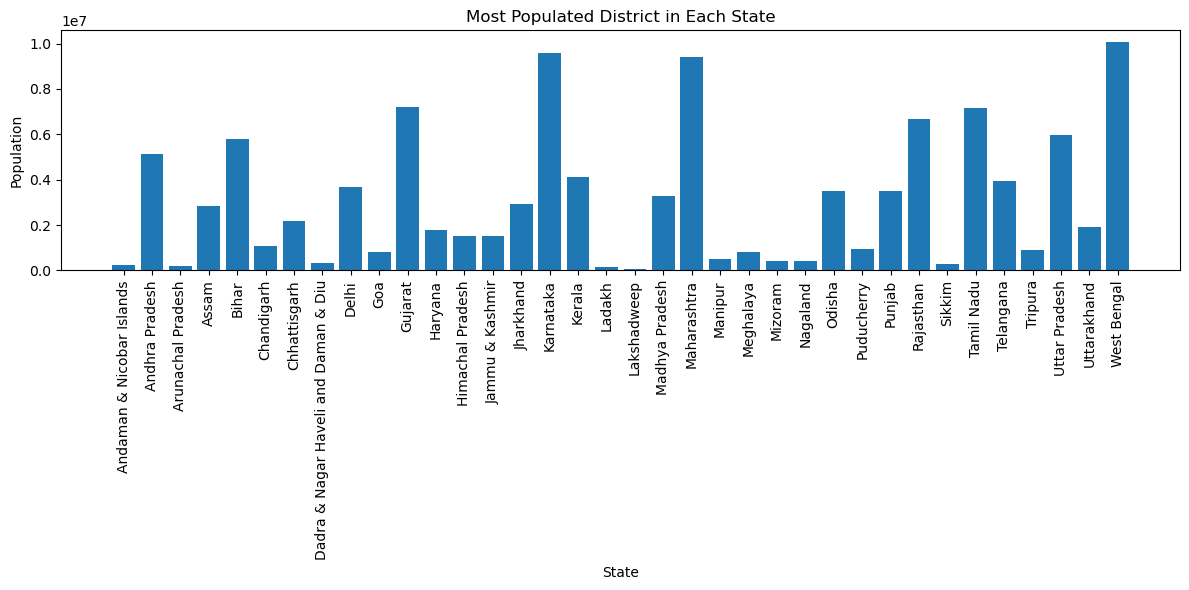

In [43]:
import matplotlib.pyplot as plt

df = datasets['District Demographics']

result = df.loc[df.groupby('State')['Population'].idxmax()]

plt.figure(figsize=(12, 6))
plt.bar(result['State'], result['Population'])

plt.xlabel('State')
plt.ylabel('Population')
plt.title('Most Populated District in Each State')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

## transaction value versus transaction volume analysis

In [111]:
state_performance = (
    state_txn_and_users
    .groupby("State", as_index=False)
    .agg(
        Total_Transactions=("Transactions", "sum"),
        Total_Amount_INR=("Amount (INR)", "sum")
    )
)

state_performance["Calculated_ATV_INR"] = (
    state_performance["Total_Amount_INR"]
    / state_performance["Total_Transactions"].replace(0, float("nan"))
)

state_performance = state_performance.sort_values(
    "Total_Transactions",
    ascending=False
)

state_performance.round(2).head(10)

,State,Total_Transactions,Total_Amount_INR,Calculated_ATV_INR
15,Karnataka,2981044533,4.361396e+12,1463.04
20,Maharashtra,2833670154,4.290995e+12,1514.29
31,Telangana,2347430243,4.574246e+12,1948.62
1,Andhra Pradesh,1781091169,3.258681e+12,1829.60
28,Rajasthan,1382918930,2.625584e+12,1898.58
33,Uttar Pradesh,1314714390,2.399757e+12,1825.31
19,Madhya Pradesh,1100253728,1.915101e+12,1740.60
8,Delhi,1011031124,1.649942e+12,1631.94
35,West Bengal,942286041,1.452707e+12,1541.68
30,Tamil Nadu,800399873,1.481448e+12,1850.88


## 1.⁠ ⁠Compute the average transaction value for each state. Display the results in a tabular format.

In [44]:
average_atv = state_txn_and_users.groupby("State")["ATV (INR)"].mean()

In [45]:
average_atv.head()

State
Andaman & Nicobar Islands    3159.266422
Andhra Pradesh               1748.091476
Arunachal Pradesh            2638.323985
Assam                        2008.495656
Bihar                        2023.316978
Name: ATV (INR), dtype: float64

#### 2.⁠ ⁠Identify the top 5 states with the highest ATV and the top 5 states with the lowest ATV. Display the results

In [46]:
top_5_ATV_state = average_atv.sort_values(ascending = False).head()
top_5_ATV_state

State
Ladakh                       3408.222984
Andaman & Nicobar Islands    3159.266422
Mizoram                      2927.517802
Lakshadweep                  2776.118701
Arunachal Pradesh            2638.323985
Name: ATV (INR), dtype: float64

In [47]:
bottom_5_ATV_state = average_atv.sort_values().head()
bottom_5_ATV_state

State
West Bengal                             1373.600590
Odisha                                  1428.137367
Dadra & Nagar Haveli and Daman & Diu    1487.395599
Maharashtra                             1516.361820
Karnataka                               1517.392249
Name: ATV (INR), dtype: float64

## 1.⁠ ⁠Calculate the total number of app opens over the years and quarters for each state. Display the results in a tabular format.

In [48]:
app_opens = state_txn_and_users.groupby(["State","Year","Quarter"])["App Opens"].sum().reset_index().sort_values(["State","Year","Quarter"])

In [49]:
app_opens.head(10)

,State,Year,Quarter,App Opens
0,Andaman & Nicobar Islands,2018,1,0
1,Andaman & Nicobar Islands,2018,2,0
2,Andaman & Nicobar Islands,2018,3,0
3,Andaman & Nicobar Islands,2018,4,0
4,Andaman & Nicobar Islands,2019,1,0
5,Andaman & Nicobar Islands,2019,2,52640
6,Andaman & Nicobar Islands,2019,3,171107
7,Andaman & Nicobar Islands,2019,4,177012
8,Andaman & Nicobar Islands,2020,1,193586
9,Andaman & Nicobar Islands,2020,2,305072


Enter state name:  Delhi


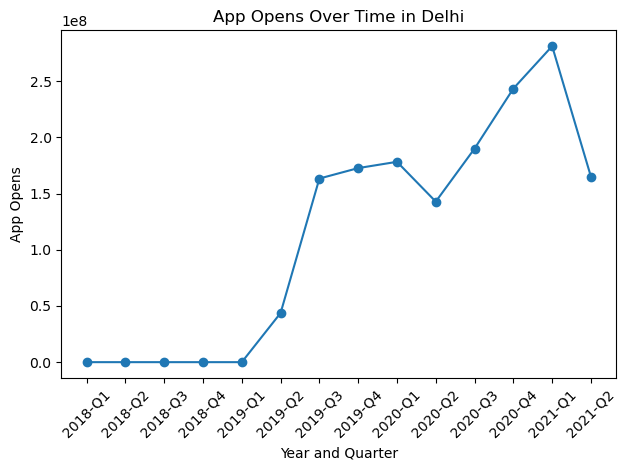

In [50]:
import matplotlib.pyplot as plt

df = datasets['State_Txn and Users']

state = input("Enter state name: ")

state_data = df[df['State'].str.lower() == state.lower()]

state_data = state_data.sort_values(['Year', 'Quarter'])

plt.plot(state_data['Year'].astype(str) + '-Q' + state_data['Quarter'].astype(str),
         state_data['App Opens'], marker='o')

plt.xlabel('Year and Quarter')
plt.ylabel('App Opens')
plt.title('App Opens Over Time in ' + state)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [51]:
# 1.⁠ ⁠Create a bar chart showing the distribution of different transaction types for each state for the most recent quarter in the dataset.


Enter Your State: Delhi


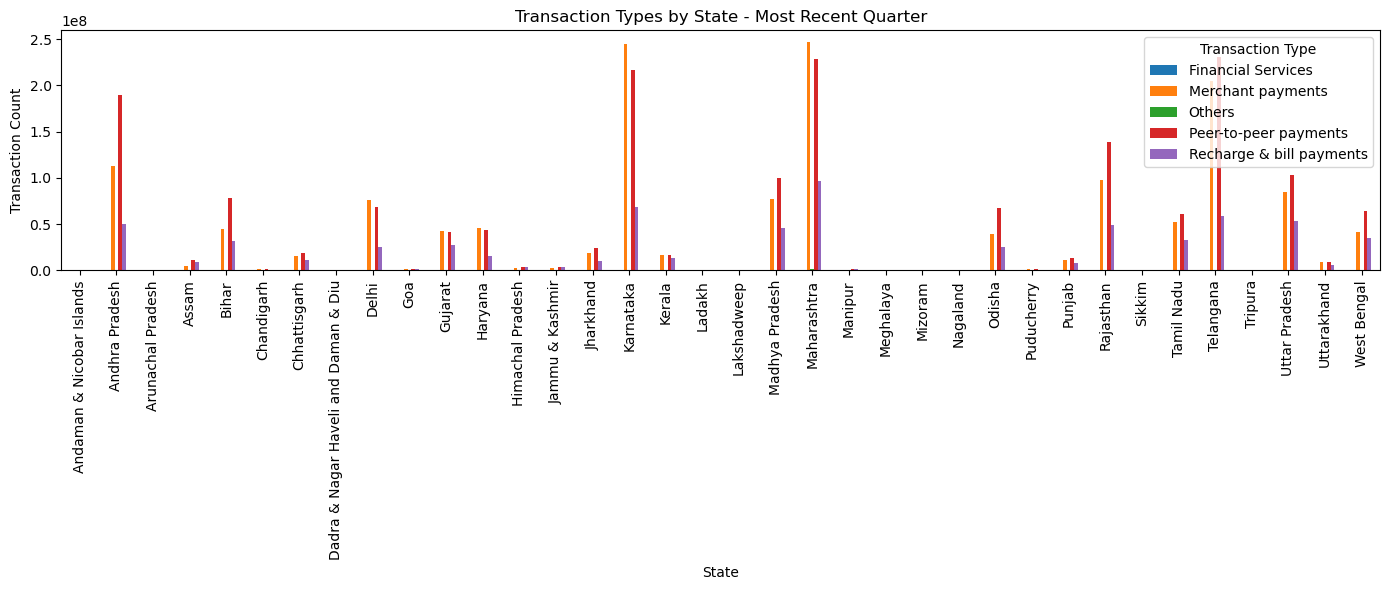

In [52]:
import matplotlib.pyplot as plt

df = datasets['State_TxnSplit']
state=input("Enter Your State:")
latest_year = df['Year'].max()
latest_quarter = df[df['Year'] == latest_year]['Quarter'].max()

result = df[(df['Year'] == latest_year) & (df['Quarter'] == latest_quarter)]

result = result.groupby(['State', 'Transaction Type'])['Transactions'].sum().reset_index()

result.pivot(index='State', columns='Transaction Type', values='Transactions').plot(kind='bar', figsize=(14, 6))

plt.xlabel('State')
plt.ylabel('Transaction Count')
plt.title('Transaction Types by State - Most Recent Quarter')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Enter state name:  Delhi


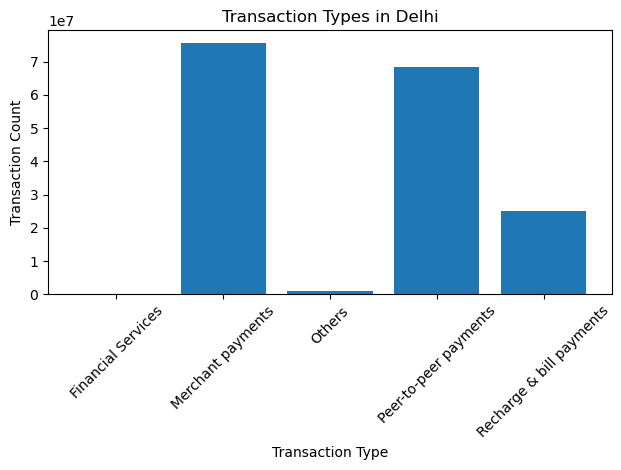

In [53]:
import matplotlib.pyplot as plt

df = datasets['State_TxnSplit']

state = input("Enter state name: ")

df = df[df['State'].str.lower() == state.lower()]

latest_year = df['Year'].max()
latest_quarter = df[df['Year'] == latest_year]['Quarter'].max()

result = df[(df['Year'] == latest_year) & (df['Quarter'] == latest_quarter)]

result = result.groupby('Transaction Type')['Transactions'].sum()

plt.bar(result.index, result.values)

plt.xlabel('Transaction Type')
plt.ylabel('Transaction Count')
plt.title('Transaction Types in ' + state)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [54]:
district_mapping = district_demographics[["District","Code"]].drop_duplicates()

In [55]:
district_mapping.head()

,District,Code
0,Anantapur,AP01
1,Chittoor,AP02
2,East Godavari,AP03
3,Guntur,AP04
4,YSR,AP13


In [56]:
district_mapping.to_csv("distict_name_code_mapping.csv",index = False)

## Task 2: Key Insights from Exploratory Data Analysis
- Transaction Growth: Total transactions increased significantly from approximately 1.08 billion in 2018 to 7.97 billion in 2020, indicating rapid growth in digital payment activity.
- State-wise Performance: Karnataka, Maharashtra, and Telangana recorded the highest cumulative transaction volumes, while smaller states and union territories recorded lower absolute volumes.
- Transaction Preferences: Peer-to-peer payments were the leading transaction type in approximately 62% of state-quarter combinations, followed by recharge and bill payments.
- Device Usage: Xiaomi appeared prominently in state-level registered-user counts, providing insights into the device composition of PhonePe's user base.
- Demographic Analysis: Identifying the most populated district in each state helped highlight potential markets for further analysis and expansion.
- Average Transaction Value (ATV): Ladakh had the highest mean ATV, while West Bengal had the lowest, showing that transaction volume and average transaction value reflect different aspects of market behavior.
- App Engagement: App opens varied across states and quarters, highlighting the importance of analyzing user engagement alongside completed transactions.

# Task 3: Data Quality Checks

## 3.1: Ensure data consistency across state and district levels

### 1.⁠ ⁠For each state, calculate the total number of transactions, total transaction amount, and total registered users by summing up the values from the district level data.

In [57]:
district_txn_and_users.head()

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1.139849e+06,2158.804548,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,9.316631e+05,2107.835016,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3.072437e+06,2743.247239,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1.317863e+06,1597.409798,911,0


In [58]:
state_for_district = district_txn_and_users.groupby("State")[["Transactions","Amount (INR)","Registered Users"]].sum()

In [59]:
state_for_district.tail()

,Transactions,Amount (INR),Registered Users
State,,,
Telangana,2347430243,4.574246e+12,149224214
Tripura,12018152,2.097051e+10,3661575
Uttar Pradesh,1314714390,2.399757e+12,246200404
Uttarakhand,124011162,2.150715e+11,23792747
West Bengal,942286041,1.452707e+12,144242183


## 2.⁠ ⁠Compare the results with the corresponding values at the state level to ensure they match

In [60]:
state_txn_and_users.head()

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,2.833854e+07,2498.989022,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,5.555747e+07,3415.768284,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,9.054834e+07,3811.277720,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,1.022997e+08,3355.630147,18596,0


In [61]:
state_level = state_txn_and_users.groupby("State")[["Transactions","Amount (INR)","Registered Users"]].sum()

In [62]:
state_level.tail()

,Transactions,Amount (INR),Registered Users
State,,,
Telangana,2347430243,4.574246e+12,149224214
Tripura,12018152,2.097051e+10,3661575
Uttar Pradesh,1314714390,2.399757e+12,246200404
Uttarakhand,124011162,2.150715e+11,23792747
West Bengal,942286041,1.452707e+12,144242183


In [63]:
comparison = state_level.merge(state_for_district,on="State",suffixes = ("_State","_District"))

In [64]:
comparison.head()

,Transactions_State,Amount (INR)_State,Registered Users_State,Transactions_District,Amount (INR)_District,Registered Users_District
State,,,,,,
Andaman & Nicobar Islands,1223565,3.641818e+09,408396,1223565,3.641818e+09,408396
Andhra Pradesh,1781091169,3.258681e+12,158007957,1781091169,3.860292e+12,158007957
Arunachal Pradesh,8043799,2.225183e+10,1862214,8043799,2.225183e+10,1862214
Assam,123577981,2.814087e+11,26860751,123577981,2.814087e+11,26860751
Bihar,713643889,1.639579e+12,115284760,713643889,1.639579e+12,115284760


In [65]:
comparison["Transaction_Match"]=(comparison["Transactions_State"]==comparison["Transactions_District"])
comparison["Amount_Match"] = np.isclose(comparison["Amount (INR)_State"],comparison["Amount (INR)_District"],rtol=1e-12,atol=1)
comparison["Users_Match"]=(comparison["Registered Users_State"]==comparison["Registered Users_District"])

In [66]:
comparison

,Transactions_State,Amount (INR)_State,Registered Users_State,Transactions_District,Amount (INR)_District,Registered Users_District,Transaction_Match,Amount_Match,Users_Match
State,,,,,,,,,
Andaman & Nicobar Islands,1223565,3.641818e+09,408396,1223565,3.641818e+09,408396,True,True,True
Andhra Pradesh,1781091169,3.258681e+12,158007957,1781091169,3.860292e+12,158007957,True,False,True
Arunachal Pradesh,8043799,2.225183e+10,1862214,8043799,2.225183e+10,1862214,True,True,True
Assam,123577981,2.814087e+11,26860751,123577981,2.814087e+11,26860751,True,True,True
Bihar,713643889,1.639579e+12,115284760,713643889,1.639579e+12,115284760,True,True,True
Chandigarh,25516542,5.371208e+10,3801466,25516542,5.371208e+10,3801466,True,True,True
Chhattisgarh,241908549,4.156353e+11,37448388,241908549,4.156353e+11,37448388,True,True,True
Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10,2701112,12462185,1.865878e+10,2701112,True,True,True
Delhi,1011031124,1.649942e+12,95374654,1011031124,1.649942e+12,95374654,True,True,True


## 3.⁠ ⁠Display any discrepancies found between the district-level and state-level data

In [67]:
discrepancies = comparison[(comparison["Transaction_Match"]== False)|(comparison["Amount_Match"]==False)| (comparison["Users_Match"]==False)]

In [68]:
discrepancies.head(5)

,Transactions_State,Amount (INR)_State,Registered Users_State,Transactions_District,Amount (INR)_District,Registered Users_District,Transaction_Match,Amount_Match,Users_Match
State,,,,,,,,,
Andhra Pradesh,1781091169,3.258681e+12,158007957,1781091169,3.860292e+12,158007957,True,False,True


# Task 4: Data Merging and Advanced Analysis

## 4.1: Ratio of users to population by state

### 1.⁠ ⁠Merge the State_Txnand Users dataset with the District Demographics dataset to calculate the ratio of registered users to the population for each state.Display the results in a tabular format

In [69]:
latest_year = state_txn_and_users["Year"].max()
latest_quarter = (state_txn_and_users[state_txn_and_users["Year"]==latest_year]["Quarter"].max())

In [70]:
latest_year

2021

In [71]:
registered_users = state_txn_and_users[(state_txn_and_users["Year"]==latest_year) & (state_txn_and_users["Quarter"]==latest_quarter)][["State","Registered Users"]]

In [72]:
registered_users.head()

,State,Registered Users
13,Andaman & Nicobar Islands,62095
27,Andhra Pradesh,19620905
41,Arunachal Pradesh,270572
55,Assam,3617056
69,Bihar,14972134


In [73]:
population = district_demographics.groupby("State")["Population"].sum().reset_index()

In [74]:
population.head()

,State,Population
0,Andaman & Nicobar Islands,380581
1,Andhra Pradesh,49378776
2,Arunachal Pradesh,1606047
3,Assam,34461385
4,Bihar,103817951


In [75]:
ratio_merge = registered_users.merge(population,on="State")

In [76]:
ratio_merge["Ratio(%)"] = (
    ratio_merge["Registered Users"] /
    ratio_merge["Population"]
) * 100

In [77]:
ratio_merge.head()

,State,Registered Users,Population,Ratio(%)
0,Andaman & Nicobar Islands,62095,380581,16.315843
1,Andhra Pradesh,19620905,49378776,39.735503
2,Arunachal Pradesh,270572,1606047,16.847079
3,Assam,3617056,34461385,10.495968
4,Bihar,14972134,103817951,14.421527


### 2.⁠ ⁠Create a column chart depicting the ratio of users to population by state

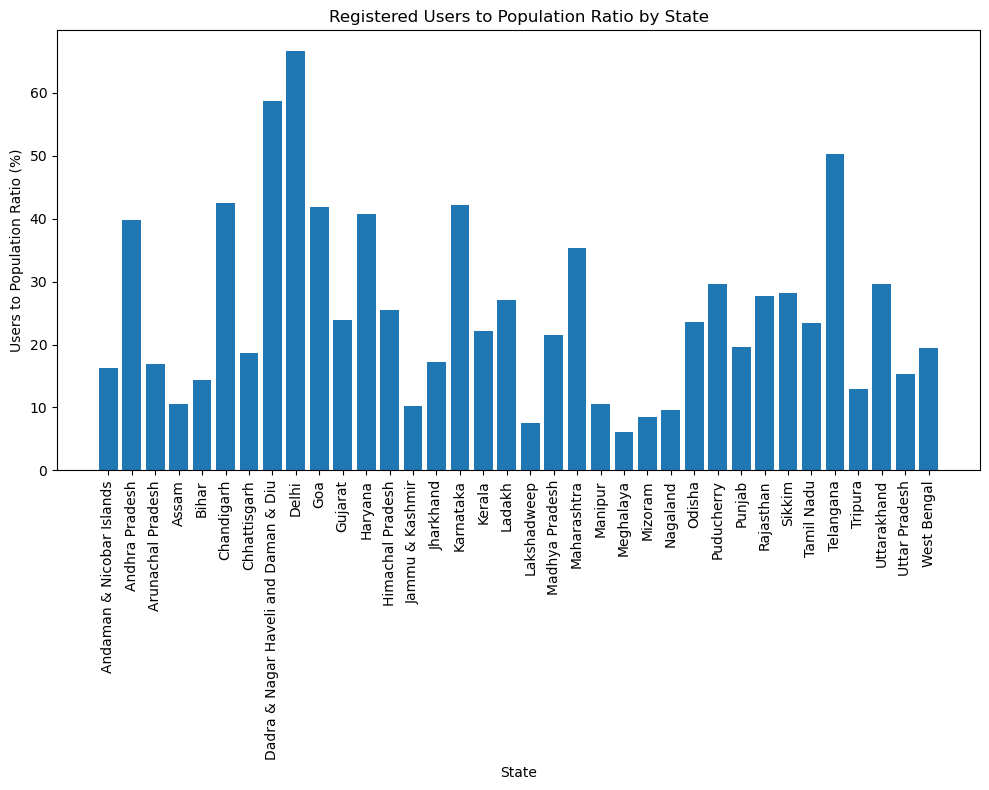

In [78]:
plt.figure(figsize = (10,8))

plt.bar(ratio_merge["State"],ratio_merge["Ratio(%)"])

plt.xlabel("State")
plt.ylabel("Users to Population Ratio (%)")
plt.title("Registered Users to Population Ratio by State")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# 4.1 Findings:
## Ratio of Users to Population
- User Penetration: By merging state-level transaction data with district demographics, I calculated the ratio of registered users to population for each state.
- Market Potential: States with higher ratios show greater registered-user penetration relative to their population, while states with lower ratios may offer opportunities for further digital-payment adoption.
- Business Insight: This metric helps compare potential markets more meaningfully than registered-user counts alone. However, registered users are not necessarily active users, and the population figures should be interpreted in the context of the dataset's coverage.

## 4.2: Correlate population density with transaction volume

### 1.⁠ ⁠Merge the District Txn and Users dataset with the District Demographics dataset

In [79]:
district_merge = district_txn_and_users.merge(district_demographics,on=["State","Code"],how = "left")

In [80]:
district_merge.head()

,State,Year,Quarter,District_x,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens,District_y,Headquarters,Population,Area (sq km),Density,Alternate Name
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1.139849e+06,2158.804548,262,0,Nicobar,Car Nicobar,36842.0,1841.0,20.0,Nicobars
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,9.316631e+05,2107.835016,632,0,North and Middle Andaman,Mayabunder,105597.0,3736.0,28.0,North and Middle Andaman
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0,South Andaman,Port Blair,238142.0,2672.0,89.0,South Andaman
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3.072437e+06,2743.247239,351,0,Nicobar,Car Nicobar,36842.0,1841.0,20.0,Nicobars
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1.317863e+06,1597.409798,911,0,North and Middle Andaman,Mayabunder,105597.0,3736.0,28.0,North and Middle Andaman


### 2.⁠ ⁠Calculate the correlation between population density and transaction volume

In [81]:
correlation = district_merge["Density"].corr(district_merge["Transactions"])

In [82]:
print("Correlation between Population Density and Transaction Volume:",correlation)

Correlation between Population Density and Transaction Volume: 0.19038897306782113


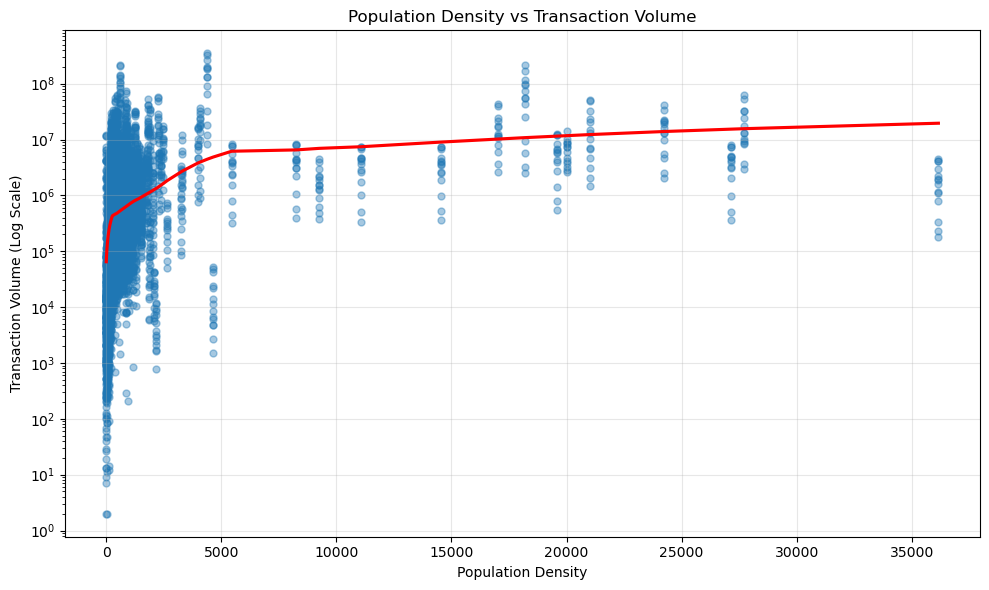

In [83]:

plt.figure(figsize=(10, 6))

sns.regplot(
    data=district_merge,
    x="Density",
    y="Transactions",
    scatter_kws={"alpha": 0.4, "s": 25},
    line_kws={"color": "red"},
    lowess=True
)

plt.yscale("log")
plt.xlabel("Population Density")
plt.ylabel("Transaction Volume (Log Scale)")
plt.title("Population Density vs Transaction Volume")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## RED LINE INDICATES
### This suggests that transaction volume may increase more rapidly across the lower density range, while the average trend changes more gradually at higher densities

### Business insights-Population density alone is not a sufficient basis for selecting expansion markets. Adoption, economic activity, merchant acceptance, and existing customer engagement may also matter

### 4.2 Correlation Between Population Density and Transaction Volume

- **Weak Positive Correlation:** The analysis produced a correlation coefficient of approximately **0.19**, indicating a weak positive relationship between population density and transaction volume.

- **Key Finding:** More densely populated districts do not necessarily generate proportionately more digital transactions. Factors such as user adoption, merchant availability, and payment habits may also influence transaction activity.

- **Business Insight:** PhonePe should evaluate districts based on transaction activity and user adoption alongside population density, rather than treating density alone as a reliable predictor of payment demand.

- **Recommendation:** Identify densely populated districts with low transaction activity and investigate opportunities to improve digital payment adoption and merchant acceptance.

## 4.3: Average transaction amount per user

### 1.⁠ ⁠Merge relevant datasets to calculate the average transaction amount per user for each state. Display the results in a tabular format

In [84]:
state_txn_and_users["Amount_Per_User"] = (state_txn_and_users["Amount (INR)"]/state_txn_and_users["Registered Users"])

In [85]:
average_Amount_per_user = state_txn_and_users.groupby("State")["Amount_Per_User"].mean().reset_index()

In [86]:
average_Amount_per_user.sort_values(by="Amount_Per_User" ,ascending=False)

,State,Amount_Per_User
31,Telangana,23774.041127
15,Karnataka,17318.863969
1,Andhra Pradesh,16527.631877
8,Delhi,14791.885162
28,Rajasthan,13708.117474
5,Chandigarh,12860.471685
25,Odisha,12378.116784
19,Madhya Pradesh,12151.251194
21,Manipur,11644.051472
4,Bihar,11287.137833


## 2.⁠ ⁠Identify the top 5 states with the highest average transaction amount per user and the top 5 states with the lowest average transaction amount per user. Display the results

In [87]:
top_5 = (average_Amount_per_user.sort_values("Amount_Per_User", ascending=False).head(5))

bottom_5 = (average_Amount_per_user.sort_values("Amount_Per_User", ascending=True).head(5))

print("Top 5 States:")
display(top_5)

print("Bottom 5 States:")
display(bottom_5)

Top 5 States:


,State,Amount_Per_User
31,Telangana,23774.041127
15,Karnataka,17318.863969
1,Andhra Pradesh,16527.631877
8,Delhi,14791.885162
28,Rajasthan,13708.117474


Bottom 5 States:


,State,Amount_Per_User
32,Tripura,4956.287167
18,Lakshadweep,5492.605845
16,Kerala,6038.016882
7,Dadra & Nagar Haveli and Daman & Diu,6168.978161
12,Himachal Pradesh,6373.195303


### 4.3 Average Transaction Amount per User

- **State-wise Comparison:** I calculated the average transaction amount per registered user and identified the top five and bottom five states based on the results.

- **Interpreting the Metric:** States with higher values generate more transaction value relative to their registered-user base, while lower values may indicate an opportunity to improve user engagement.

- **Business Insight:** This metric helps distinguish states with large user bases from those generating greater transaction value per registered user. It should be interpreted as a proxy for activity, not as the actual spending of every individual user.

## 4.4: Device brand usage ratio

### 1.⁠ ⁠Merge the State_DeviceData dataset with the State_Txn and Users dataset

In [88]:
device_merge = state_devicedata.merge(state_txn_and_users,on=["State", "Year", "Quarter"],how="left",suffixes=("_Device", "_State"))

In [89]:
device_merge.head()

,State,Year,Quarter,Brand,Registered Users_Device,Percentage,Transactions,Amount (INR),ATV (INR),Registered Users_State,App Opens,Amount_Per_User
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.247033,6658,1.463176e+07,2197.621091,6740,0,2170.884454
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.214392,6658,1.463176e+07,2197.621091,6740,0,2170.884454
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.145697,6658,1.463176e+07,2197.621091,6740,0,2170.884454
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.074332,6658,1.463176e+07,2197.621091,6740,0,2170.884454
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.049258,6658,1.463176e+07,2197.621091,6740,0,2170.884454


### 2.⁠ ⁠Calculate the ratio of users using each device brand to the total number of registered users in each state. Display the results in a tabular format

In [90]:
device_merge["Device_Usage_Ratio"] = (device_merge["Registered Users_Device"]/device_merge["Registered Users_State"])*100

In [91]:
device_merge.head()

,State,Year,Quarter,Brand,Registered Users_Device,Percentage,Transactions,Amount (INR),ATV (INR),Registered Users_State,App Opens,Amount_Per_User,Device_Usage_Ratio
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.247033,6658,1.463176e+07,2197.621091,6740,0,2170.884454,24.703264
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.214392,6658,1.463176e+07,2197.621091,6740,0,2170.884454,21.439169
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.145697,6658,1.463176e+07,2197.621091,6740,0,2170.884454,14.569733
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.074332,6658,1.463176e+07,2197.621091,6740,0,2170.884454,7.433234
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.049258,6658,1.463176e+07,2197.621091,6740,0,2170.884454,4.925816


## 3.⁠ ⁠Create a bar chart depicting the device brand usage ratio for each state

In [92]:
latest_device_data = device_merge[(device_merge["Year"] == latest_year) &(device_merge["Quarter"] == latest_quarter)]

In [93]:
device_ratio = latest_device_data.pivot(index = "State",columns = "Brand",values ="Device_Usage_Ratio")

In [94]:
device_ratio.head()

Brand,Apple,Asus,Gionee,HMD Global,Huawei,Infinix,Lava,Lenovo,Micromax,Motorola,OnePlus,Oppo,Others,Realme,Samsung,Tecno,Vivo,Xiaomi
State,,,,,,,,,,,,,,,,,,
Andaman & Nicobar Islands,1.856832,NaN,NaN,NaN,2.510669,NaN,NaN,NaN,NaN,1.697399,3.190273,8.786537,7.350028,6.496497,18.481359,1.568564,24.246719,23.815122
Andhra Pradesh,2.296984,NaN,NaN,NaN,2.244157,NaN,NaN,1.331238,NaN,2.563959,2.012400,11.075111,6.482132,9.264629,19.358179,NaN,18.205786,25.165424
Arunachal Pradesh,1.870851,NaN,0.927664,NaN,0.889966,NaN,NaN,NaN,NaN,0.823810,0.969058,15.673093,5.423695,8.308694,18.889612,NaN,23.446255,22.777301
Assam,1.150715,1.254169,1.149388,NaN,1.436472,NaN,NaN,NaN,NaN,1.183863,NaN,13.918723,9.551110,9.920803,14.452776,NaN,20.843470,25.138510
Bihar,NaN,NaN,NaN,NaN,1.440055,1.420646,NaN,1.029593,NaN,1.430257,NaN,12.201554,7.657372,10.522054,19.296267,1.054973,15.438527,28.508702


Enter state name:  Delhi


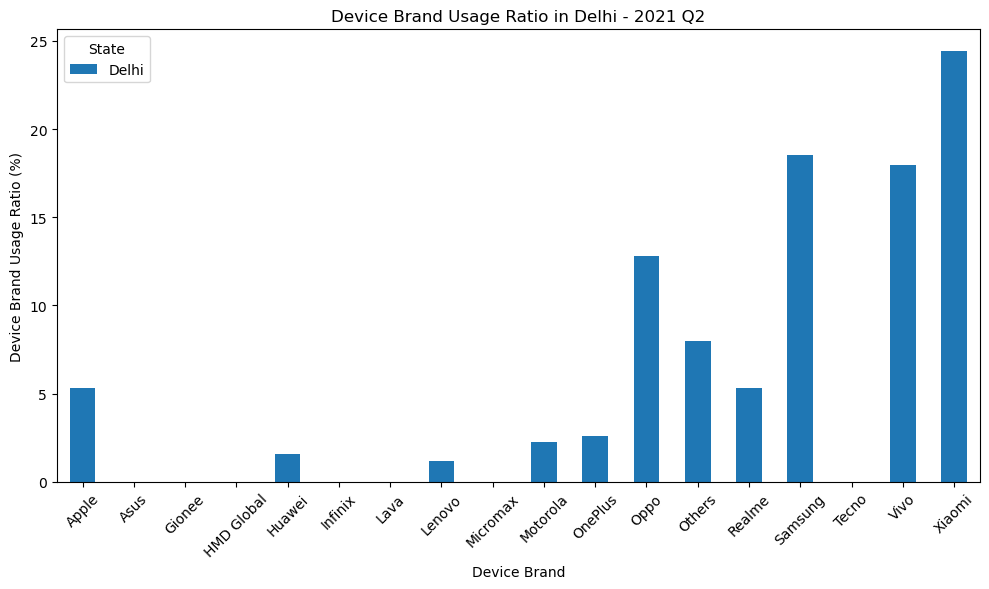

In [95]:

state_name = input("Enter state name: ")

# Filter data for the selected state
state_data = device_ratio.loc[device_ratio.index == state_name]

if state_data.empty:
    print("State not found. Please check the state name.")
else:
    state_data.T.plot(kind="bar", figsize=(10, 6))

    plt.xlabel("Device Brand")
    plt.ylabel("Device Brand Usage Ratio (%)")
    plt.title(f"Device Brand Usage Ratio in {state_name} - 2021 Q2")

    plt.xticks(rotation=45)
    plt.legend(title="State")
    plt.tight_layout()
    plt.show()


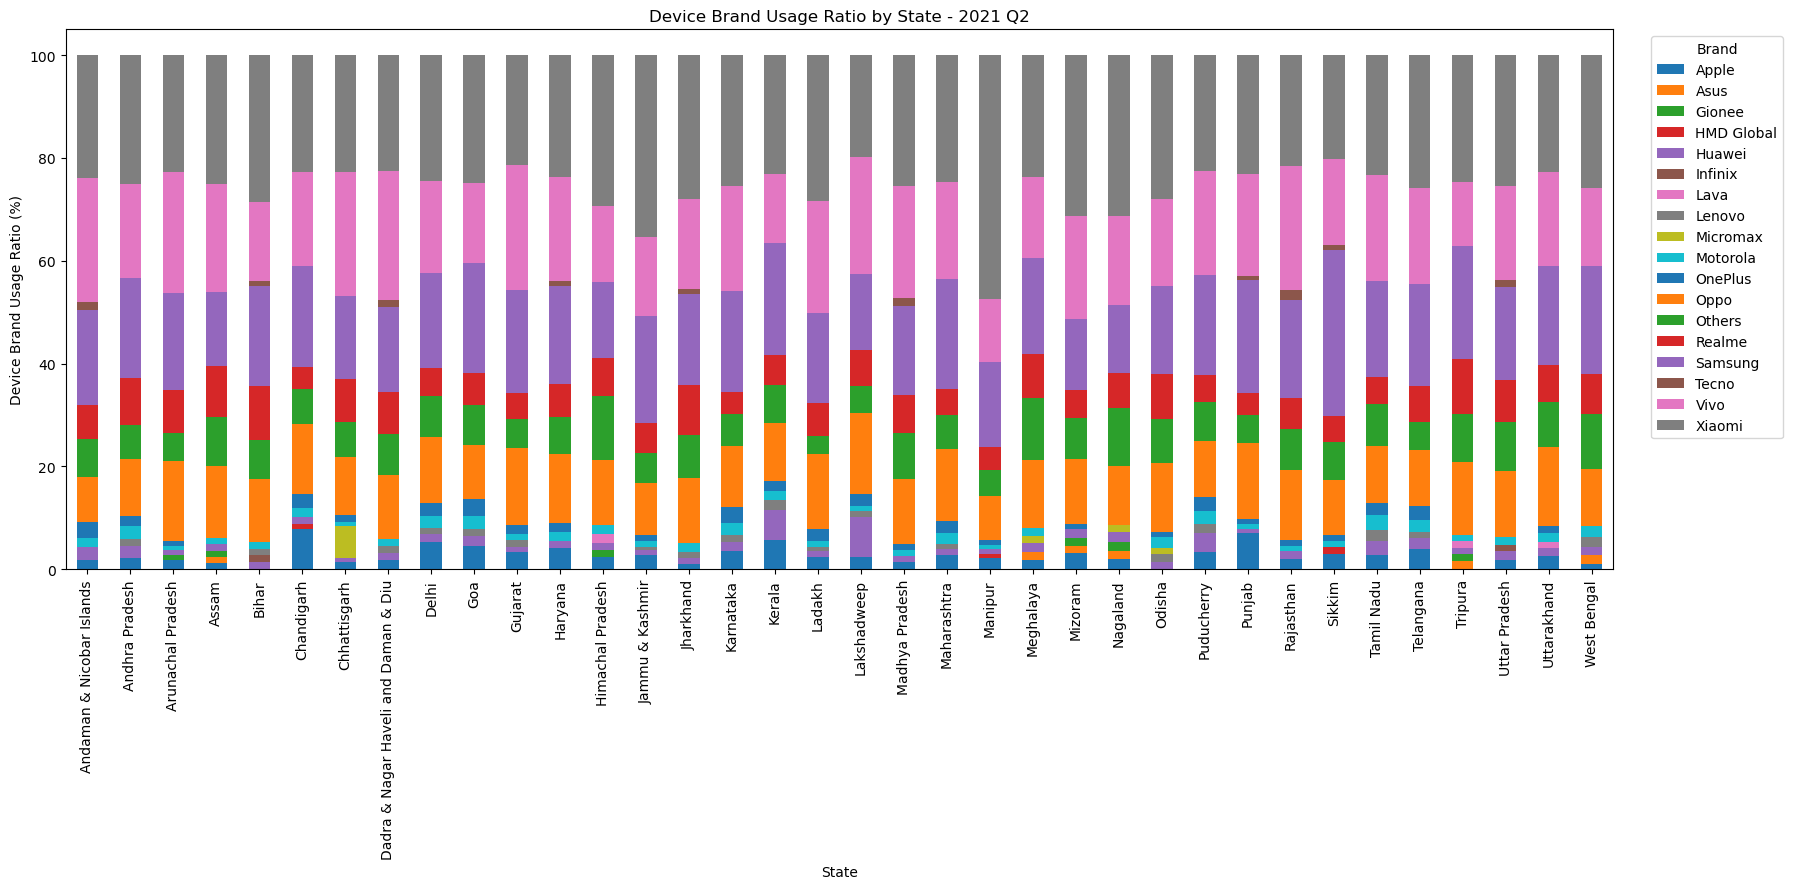

In [96]:
device_ratio = (
    latest_device_data
    .pivot(
        index="State",
        columns="Brand",
        values="Device_Usage_Ratio"
    )
)

ax = device_ratio.plot(
    kind="bar",
    stacked=True,
    figsize=(18, 9)
)

plt.xlabel("State")
plt.ylabel("Device Brand Usage Ratio (%)")
plt.title("Device Brand Usage Ratio by State - 2021 Q2")

plt.xticks(rotation=90)

plt.legend(
    title="Brand",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### 4.4 Device Brand Usage Ratio

- **Device Preferences:** By combining device-brand data with state-level user data, I calculated the share of registered users associated with each device brand.

- **Comparative Analysis:** The resulting ratios help identify which brands have a larger presence in each state's registered-user base.

- **Business Insight:** Understanding device distribution can help PhonePe assess its user base across device categories and investigate whether device preferences are associated with differences in adoption or engagement.

## State level Growth

In [112]:
state_yearly = (
    state_txn_and_users
    .groupby(["State", "Year"], as_index=False)
    .agg(Total_Transactions=("Transactions", "sum"))
)

# Compare the first and last available years
first_year = state_yearly["Year"].min()
last_year = state_yearly["Year"].max()

first_data = (
    state_yearly[state_yearly["Year"] == first_year]
    [["State", "Total_Transactions"]]
    .rename(columns={"Total_Transactions": "First_Year_Transactions"})
)

last_data = (
    state_yearly[state_yearly["Year"] == last_year]
    [["State", "Total_Transactions"]]
    .rename(columns={"Total_Transactions": "Last_Year_Transactions"})
)

state_growth = first_data.merge(last_data, on="State", how="inner")

state_growth["Growth_%"] = (
    (
        state_growth["Last_Year_Transactions"]
        - state_growth["First_Year_Transactions"]
    )
    / state_growth["First_Year_Transactions"].replace(0, float("nan"))
) * 100

state_growth = state_growth.sort_values("Growth_%", ascending=False)

state_growth.round(2).head(10)

,State,First_Year_Transactions,Last_Year_Transactions,Growth_%
31,Telangana,67541293,908439654,1245.01
15,Karnataka,99925678,1054446538,955.23
28,Rajasthan,52782208,540207958,923.47
0,Andaman & Nicobar Islands,58021,586166,910.27
26,Puducherry,732708,7060819,863.66
20,Maharashtra,116301535,1091476726,838.49
17,Ladakh,81174,675131,731.71
1,Andhra Pradesh,77779112,642515104,726.08
21,Manipur,661158,5389810,715.21
9,Goa,1244738,10041684,706.73


## Overall Business Recommendations(Task 4)

### 1. Expand into Underpenetrated Markets
Prioritize states with large populations and low registered-user penetration. Track new registrations, first transactions, and repeat usage.

### 2. Improve Merchant Acceptance
Investigate districts where transaction volume is low relative to population density. Work with local merchants to increase the number of places accepting digital payments.

### 3. Increase Engagement and Payment Frequency
Encourage customers to use PhonePe for routine payments, bills, and merchant purchases. Measure repeat transactions and active-user rates, not only transaction amount.

### 4. Improve the Mobile Experience
Use device-brand data to prioritize compatibility, performance testing, and troubleshooting on commonly used devices.

### 5. Measure Business Outcomes
Track active users, transactions per active user, merchant-payment share, repeat usage, and transaction value by state and district. This will help determine whether growth initiatives are working.

# Task 5: Data Visualization

## 5.0  Year on year growth analysis

In [113]:
import pandas as pd

yearly_growth = (
    state_txn_and_users
    .groupby("Year", as_index=False)
    .agg(
        Total_Transactions=("Transactions", "sum"),
        Total_Amount_INR=("Amount (INR)", "sum"),
        Total_Registered_Users=("Registered Users", "sum")
    )
    .sort_values("Year")
)

yearly_growth["Transaction_Growth_%"] = (
    yearly_growth["Total_Transactions"].pct_change() * 100
)

yearly_growth["Amount_Growth_%"] = (
    yearly_growth["Total_Amount_INR"].pct_change() * 100
)

yearly_growth["User_Growth_%"] = (
    yearly_growth["Total_Registered_Users"].pct_change() * 100
)

yearly_growth.round(2)

,Year,Total_Transactions,Total_Amount_INR,Total_Registered_Users,Transaction_Growth_%,Amount_Growth_%,User_Growth_%
0,2018,1080202410,1.623045e+12,292797872,NaN,NaN,NaN
1,2019,4079827215,6.276688e+12,602811578,277.69,286.72,105.88
2,2020,7973974741,1.464116e+13,922009385,95.45,133.26,52.95
3,2021,7398955928,1.315910e+13,590241612,-7.21,-10.12,-35.98


## 5.1: Plot the total transactions and amount over time for a selected state

### 1.⁠ ⁠Create a line plot showing the total number of transactions and the total transaction amount over time (years and quarters) for a selected state.

Enter state name:  Delhi


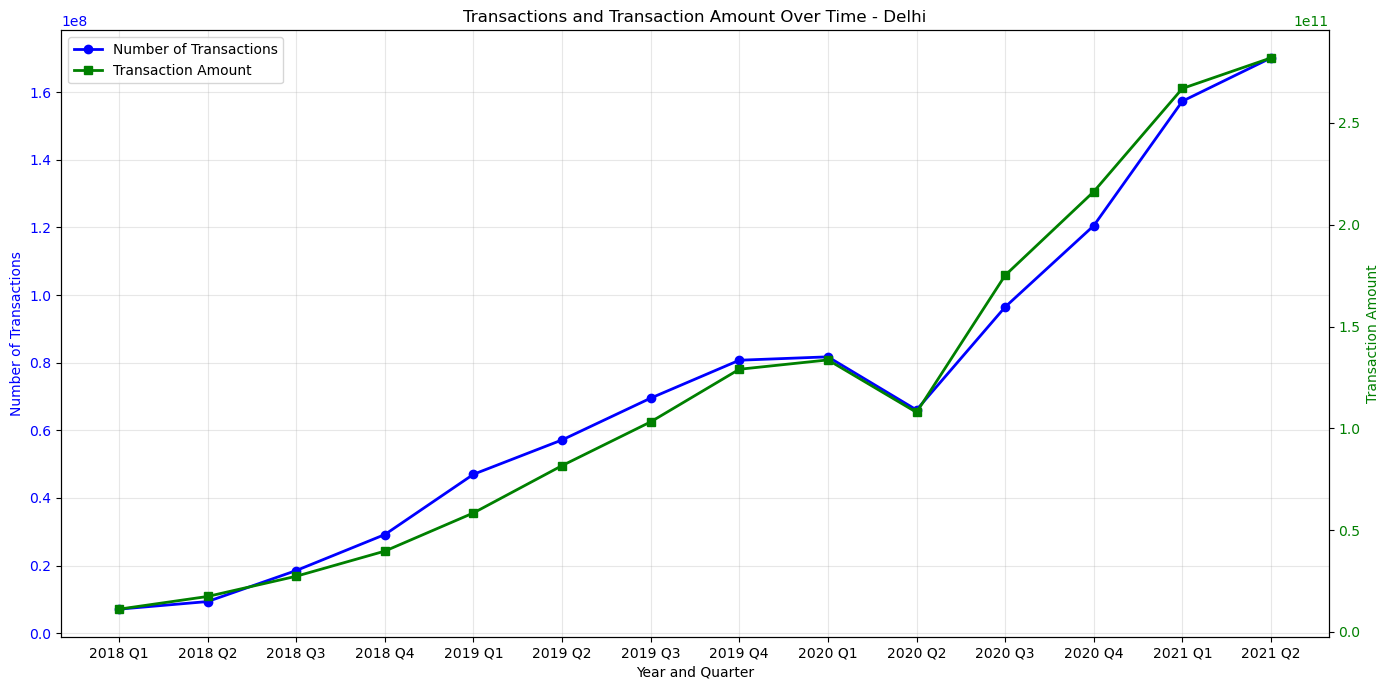

In [97]:

import pandas as pd
import matplotlib.pyplot as plt

selected_state = input("Enter state name: ")

state_data = state_txn_and_users[
    state_txn_and_users["State"].str.strip().str.lower()
    == selected_state.strip().lower()
].copy()

state_data = state_data.sort_values(["Year", "Quarter"])

state_data["Time"] = (
    state_data["Year"].astype(str)
    + " Q"
    + state_data["Quarter"].astype(str)
)

fig, ax1 = plt.subplots(figsize=(14, 7))

# Line 1: Number of transactions
line1, = ax1.plot(
    state_data["Time"],
    state_data["Transactions"],
    color="blue",
    marker="o",
    linewidth=2,
    label="Number of Transactions"
)

ax1.set_xlabel("Year and Quarter")
ax1.set_ylabel("Number of Transactions", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")

# Line 2: Transaction amount on a second y-axis
ax2 = ax1.twinx()

line2, = ax2.plot(
    state_data["Time"],
    state_data["Amount (INR)"],
    color="green",
    marker="s",
    linewidth=2,
    label="Transaction Amount"
)

ax2.set_ylabel("Transaction Amount", color="green")
ax2.tick_params(axis="y", labelcolor="green")

# Combined legend for both lines
ax1.legend(
    handles=[line1, line2],
    labels=["Number of Transactions", "Transaction Amount"],
    loc="upper left"
)

plt.title(f"Transactions and Transaction Amount Over Time - {selected_state}")
plt.xticks(rotation=45)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


“I plotted Delhi's quarterly transaction count and transaction amount from 2018 Q1 to 2021 Q2. Both showed substantial overall growth, with a temporary dip in Q2 2020 followed by a strong recovery and a peak in Q2 2021.”

## 5.2: Create a pie chart showing distribution of Different Transaction Types for a Selected state

In [98]:

# Select only Year and Quarter
merged_data = state_txnsplit[["Year", "Quarter"]].drop_duplicates()

# Sort chronologically
merged_data = merged_data.sort_values(["Year", "Quarter"]).reset_index(drop=True)

# Print the DataFrame
print(merged_data.to_string(index=False))


 Year  Quarter
 2018        1
 2018        2
 2018        3
 2018        4
 2019        1
 2019        2
 2019        3
 2019        4
 2020        1
 2020        2
 2020        3
 2020        4
 2021        1
 2021        2


Enter state name:  Delhi
Enter year (e.g., 2021):  2021
Enter quarter (1-4):  1


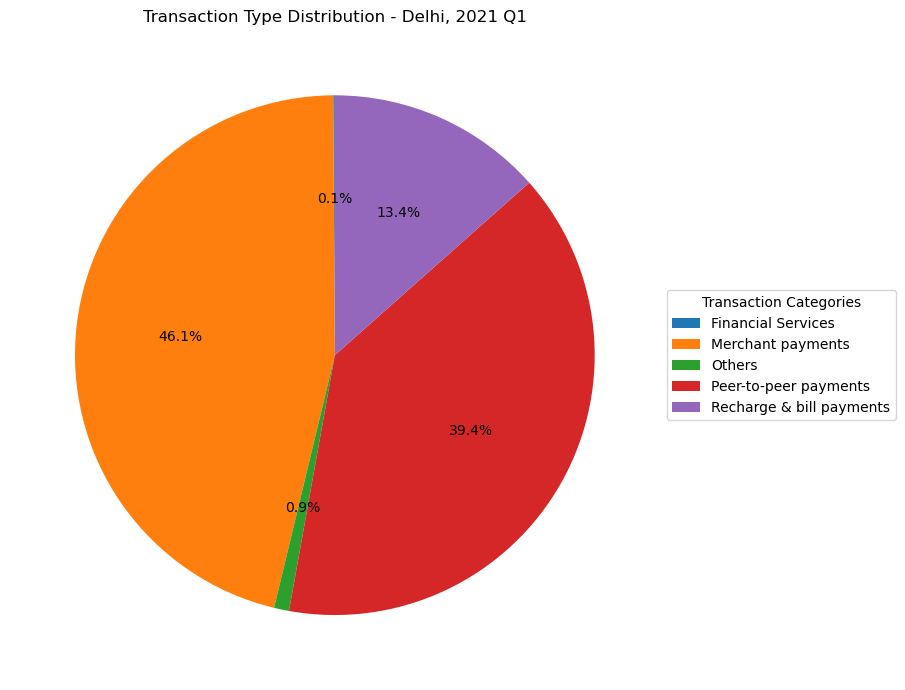

In [110]:

import pandas as pd
import matplotlib.pyplot as plt

# Take user input
selected_state = input("Enter state name: ")
selected_year = int(input("Enter year (e.g., 2021): "))
selected_quarter = int(input("Enter quarter (1-4): "))

# Filter data for the selected state, year, and quarter
filtered_data = state_txnsplit[
    (state_txnsplit["State"].str.strip().str.lower() == selected_state.strip().lower()) &
    (state_txnsplit["Year"] == selected_year) &
    (state_txnsplit["Quarter"] == selected_quarter)
].copy()

# Group transactions by transaction type
transaction_summary = filtered_data.groupby("Transaction Type")[
    "Transactions"
].sum()

# Create pie chart

plt.figure(figsize=(12, 7))

plt.pie(
    transaction_summary,
    labels=None,
    autopct="%1.1f%%",
    startangle=90
)

plt.title(
    f"Transaction Type Distribution - {selected_state}, "
    f"{selected_year} Q{selected_quarter}"
)

# Display categories as a legend on the right
plt.legend(
    transaction_summary.index,
    title="Transaction Categories",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.tight_layout()
plt.show()


### Business Takeaway

Merchant payments and peer-to-peer payments together accounted for approximately **78.6% of Delhi's transactions in Q3 2019**. This suggests that these two use cases were the primary drivers of transaction activity in the selected period, while financial services represented a comparatively small share.

## 5.3: Visualize the population density of districts in a selected state

Enter your state: Delhi


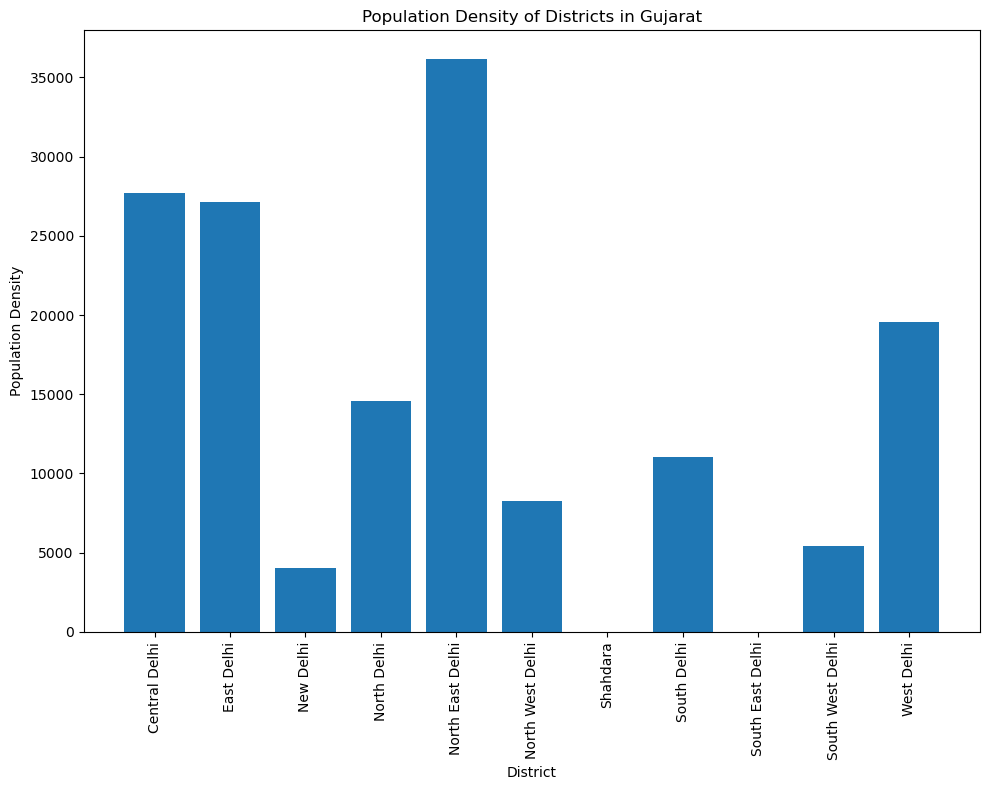

In [100]:
selected_state = input("Enter your state:")
selected_density = district_demographics[district_demographics["State"]==selected_state].copy()

plt.figure(figsize = (10,8))
plt.bar(selected_density["District"],
       selected_density["Density"])

plt.xlabel("District")
plt.ylabel("Population Density")
plt.title("Population Density of Districts in {selected_state}")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

### Business Takeaway

Population density varies significantly across Delhi's districts. Highly dense districts may offer opportunities for greater digital-payment adoption due to concentrated populations and potential merchant activity.

# Task 6: Insights and Conclusions [Advanced Section]

## 6.1: Identify any trends or patterns in the transaction data

### 1.⁠ ⁠Analyze the transaction data to identify any noticeable trends or patterns

In [101]:

transaction_trend = (
    state_txn_and_users
    .groupby(["Year", "Quarter"])[
        ["Transactions", "Amount (INR)"]
    ]
    .sum()
    .reset_index()
    .sort_values(["Year", "Quarter"])
)

# Convert transaction count into crores
transaction_trend["Transactions (Crores)"] = (
    transaction_trend["Transactions"] / 10000000
)

# Convert transaction amount into INR crores
transaction_trend["Amount (Crores)"] = (
    transaction_trend["Amount (INR)"] / 10000000
)

# Create Year-Quarter label
transaction_trend["Period"] = (
    transaction_trend["Year"].astype(str)
    + " Q"
    + transaction_trend["Quarter"].astype(str)
)

# Display values rounded to 2 decimal places
print(
    transaction_trend[
        ["Year", "Quarter", "Transactions (Crores)",
         "Amount (Crores)", "Period"]
    ].round(2).to_string(index=False)
)



 Year  Quarter  Transactions (Crores)  Amount (Crores)  Period
 2018        1                  13.44         17183.34 2018 Q1
 2018        2                  18.74         30437.42 2018 Q2
 2018        3                  34.13         47510.15 2018 Q3
 2018        4                  41.71         67173.62 2018 Q4
 2019        1                  70.90         99002.14 2019 Q1
 2019        2                  81.54        135421.40 2019 Q2
 2019        3                 109.50        167255.90 2019 Q3
 2019        4                 146.04        225989.37 2019 Q4
 2020        1                 162.30        269711.25 2020 Q1
 2020        2                 144.86        264614.51 2020 Q2
 2020        3                 203.31        390205.30 2020 Q3
 2020        4                 286.93        539585.14 2020 Q4
 2021        1                 345.76        568263.21 2021 Q1
 2021        2                 394.14        747646.60 2021 Q2


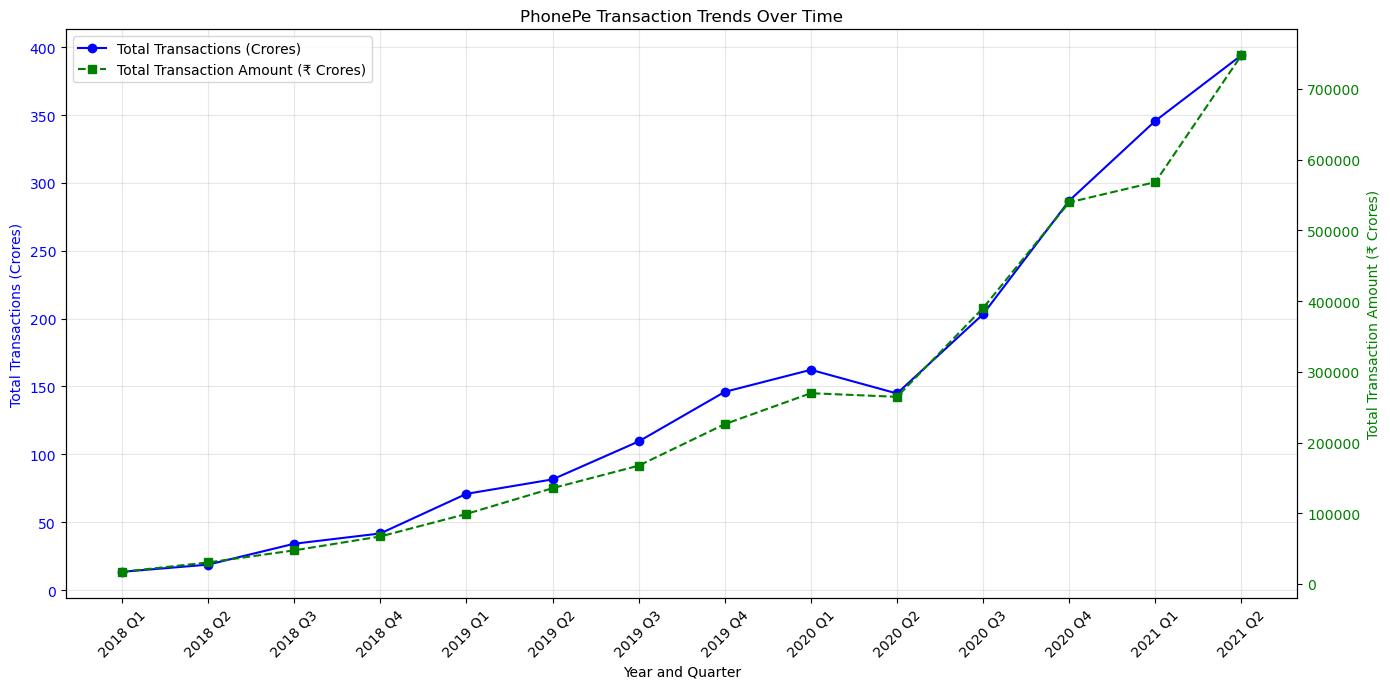

In [102]:

fig, ax1 = plt.subplots(figsize=(14, 7))

# Transactions in crores
ax1.plot(
    transaction_trend["Period"],
    transaction_trend["Transactions (Crores)"],
    color="blue",
    marker="o",
    label="Total Transactions (Crores)"
)

ax1.set_xlabel("Year and Quarter")
ax1.set_ylabel("Total Transactions (Crores)", color="blue")
ax1.tick_params(axis="y", labelcolor="blue")
ax1.tick_params(axis="x", rotation=45)

# Transaction amount in INR crores
ax2 = ax1.twinx()

ax2.plot(
    transaction_trend["Period"],
    transaction_trend["Amount (Crores)"],
    color="green",
    marker="s",
    linestyle="--",
    label="Total Transaction Amount (₹ Crores)"
)

ax2.set_ylabel("Total Transaction Amount (₹ Crores)", color="green")
ax2.tick_params(axis="y", labelcolor="green")

plt.title("PhonePe Transaction Trends Over Time")

# Combine legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc="upper left"
)

ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 6.1 Insights and Trends in Transaction Data

- **Overall Growth:** Transactions and transaction amounts increased significantly from 2018 to 2021.
- **Rapid Expansion:** Transaction activity grew steadily throughout 2019.
- **Temporary Decline:** Both metrics dipped slightly in Q2 2020 before recovering.
- **Strong Recovery:** Transaction activity increased sharply from Q3 2020 onward.
- **Peak Performance:** Q2 2021 recorded the highest transaction volume and amount.
- **Positive Relationship:** Transaction volume and total transaction amount followed similar trends.

**Conclusion:** PhonePe experienced strong growth in digital payments. Continued infrastructure improvements and analysis of quarterly fluctuations can help sustain this growth.

# 6.2: Correlate demographic data with transaction data

# 1.⁠ ⁠Finding correlations between demographic data  and transaction data 

['State', 'Year', 'Quarter', 'District', 'Code_x', 'Transactions', 'Amount (INR)', 'ATV (INR)', 'Registered Users', 'App Opens', 'Headquarters', 'Population', 'Area (sq km)', 'Density', 'Code_y', 'Alternate Name']

Correlation Matrix:
                  Population  Transactions  Amount (INR)  Registered Users  \
Population              1.00          0.36          0.35              0.66   
Transactions            0.36          1.00          0.98              0.80   
Amount (INR)            0.35          0.98          1.00              0.78   
Registered Users        0.66          0.80          0.78              1.00   
App Opens               0.42          0.84          0.84              0.86   

                  App Opens  
Population             0.42  
Transactions           0.84  
Amount (INR)           0.84  
Registered Users       0.86  
App Opens              1.00  


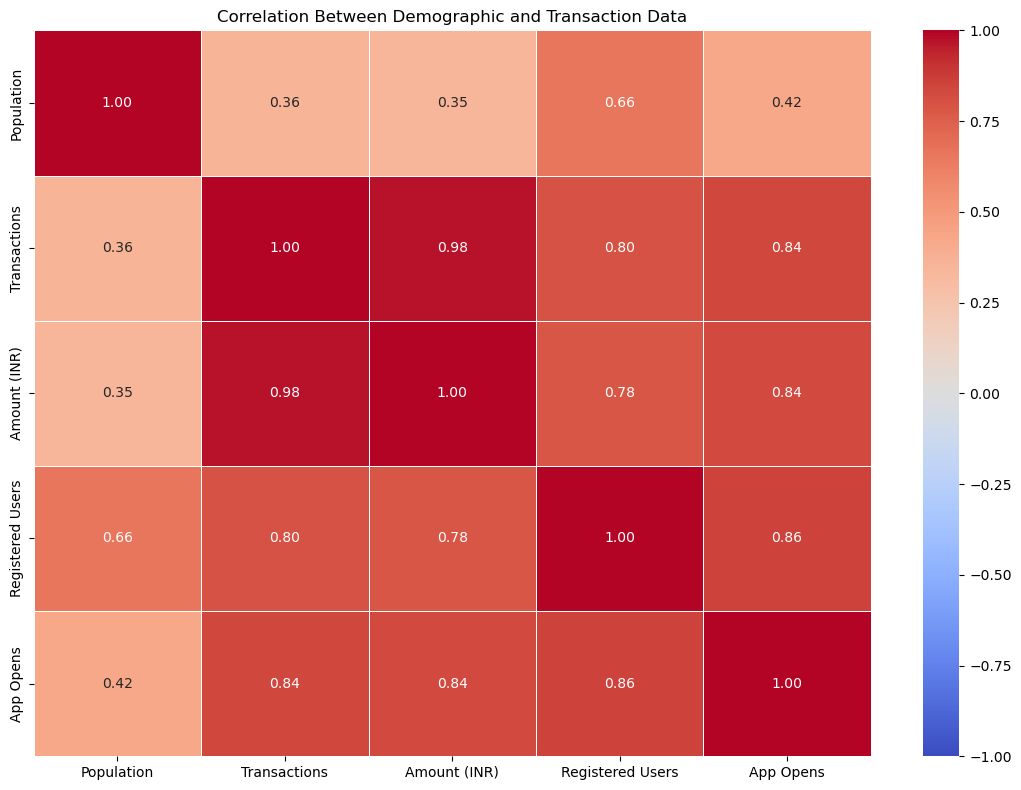

In [103]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Merge district transaction data with demographic data
merged_data = pd.merge(
    district_txn_and_users,
    district_demographics,
    on=["State", "District"],
    how="inner"
)

# Display available columns to verify their names
print(merged_data.columns.tolist())

# Select relevant numeric columns
correlation_columns = [
    "Population",
    "Population Density",
    "Transactions",
    "Amount (INR)",
    "Registered Users",
    "App Opens"
]

# Keep only columns that exist in the merged dataset
correlation_columns = [
    col for col in correlation_columns
    if col in merged_data.columns
]

correlation_data = merged_data[correlation_columns].copy()

# Convert selected columns to numeric if necessary
correlation_data = correlation_data.apply(
    pd.to_numeric, errors="coerce"
)

# Calculate correlation matrix
correlation_matrix = correlation_data.corr()

print("\nCorrelation Matrix:")
print(correlation_matrix.round(2))

# Plot correlation heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5
)

plt.title("Correlation Between Demographic and Transaction Data")
plt.tight_layout()
plt.show()



## Findings and Conclusion: Correlation Between Demographic and Transaction Data

### Key Findings

- **Transactions and Amount:** A strong positive correlation of **0.98** indicates that higher transaction volumes are associated with higher transaction amounts.
- **App Engagement:** App opens strongly correlate with transactions (0.84) and transaction amount (0.84).
- **Registered Users:** Registered users show strong correlations with transactions (0.80) and app opens (0.86).
- **Population Impact:** Population has a moderate correlation with registered users (0.66), but weaker correlations with transactions (0.36) and transaction amount (0.35).
- **User Adoption:** Registered users and app engagement appear more closely associated with transaction activity than population alone.
- **Overall Relationship:** All variables show positive correlations, with no negative relationships observed in the matrix.

### Conclusion

PhonePe's transaction activity is more strongly associated with registered users and app engagement than with population alone. The company should focus on increasing user adoption and app engagement, 
 particularly in densely populated districts with relatively low transaction activity. Investigating districts with high app opens but lower transaction volumes may also reveal opportunities to increase completed payments.

*Note: Correlation indicates association, not causation. These findings should be treated as exploratory insights.*

## Actionable insight: PhonePe should identify highly populated districts with comparatively low registered-user counts or transaction activity and investigate opportunities to improve adoption and engagement.

## 6.3: Summarize findings and insights

### 1.⁠ ⁠Summarize the key findings and insights from your analysis. Provide actionable recommendations based on the data.

## Task 6.3: Overall Findings, Insights and Recommendations

### 1. Key Findings

- **Digital Payment Growth:** Transaction volume increased substantially from 2018 to 2020. The 2021 data covers only Q1 and Q2, so it should not be compared directly with full-year totals.
- **State-wise Performance:** Karnataka, Maharashtra, and Telangana recorded the highest cumulative transaction volumes, highlighting differences in digital-payment activity across states.
- **Transaction Preferences:** Peer-to-peer payments ranked first in approximately 61.7% of state-quarter combinations, followed by recharge and bill payments at 32.1%.
- **Delhi Transaction Mix:** In Q3 2019, merchant and peer-to-peer payments together accounted for 78.6% of Delhi's transactions, making them the dominant use cases during that period.
- **User Engagement:** Transaction count and transaction amount had a strong positive correlation of approximately 0.98. App opens and transaction count also showed a positive correlation of approximately 0.84.
- **Population Density:** Population density had a weak positive correlation with transaction volume of approximately 0.19, suggesting that density alone does not explain transaction activity.
- **Data Quality:** State-level and district-level transaction amounts differed for Andhra Pradesh, requiring further investigation before reporting.
- **Customer and Device Analysis:** User penetration, transaction value per registered user, and device-brand distribution provided additional ways to compare markets and understand the customer base.

### 2. Business Recommendations

1. **Strengthen High-Volume Markets:** Improve payment reliability and customer retention in states with high transaction volumes.
2. **Increase User Engagement:** Identify registered users who transact infrequently and encourage regular use through relevant payment services and offers.
3. **Expand Merchant Payments:** Investigate opportunities to increase merchant acceptance and payment frequency, particularly in markets with growth potential.
4. **Improve Data Quality:** Reconcile state and district totals by checking aggregation logic, missing records, duplicate data, and reporting periods.
5. **Use Multiple Metrics:** Evaluate population, user penetration, transaction volume, and transaction value together when selecting target markets.
6. **Monitor Performance:** Build quarterly dashboards to track transaction growth, payment-type trends, and changes in user engagement.

### Conclusion

The analysis shows substantial growth in digital payments, significant variation across states, and a strong relationship between transaction count and transaction amount. It also highlights that population density alone is not a reliable predictor of transaction activity. PhonePe can use these insights to identify growth opportunities, improve customer engagement, strengthen merchant adoption, and make more data-driven decisions.

## year-over-year growth analysis

In [104]:
import pandas as pd

yearly_growth = (
    state_txn_and_users
    .groupby("Year", as_index=False)
    .agg(
        Total_Transactions=("Transactions", "sum"),
        Total_Amount_INR=("Amount (INR)", "sum"),
        Total_Registered_Users=("Registered Users", "sum")
    )
    .sort_values("Year")
)

yearly_growth["Transaction_Growth_%"] = (
    yearly_growth["Total_Transactions"].pct_change() * 100
)

yearly_growth["Amount_Growth_%"] = (
    yearly_growth["Total_Amount_INR"].pct_change() * 100
)

yearly_growth["User_Growth_%"] = (
    yearly_growth["Total_Registered_Users"].pct_change() * 100
)

yearly_growth.round(2)

,Year,Total_Transactions,Total_Amount_INR,Total_Registered_Users,Transaction_Growth_%,Amount_Growth_%,User_Growth_%
0,2018,1080202410,1.623045e+12,292797872,NaN,NaN,NaN
1,2019,4079827215,6.276688e+12,602811578,277.69,286.72,105.88
2,2020,7973974741,1.464116e+13,922009385,95.45,133.26,52.95
3,2021,7398955928,1.315910e+13,590241612,-7.21,-10.12,-35.98
